# BTL1 – Phân loại SPAM/HAM bình luận Facebook của sinh viên PTIT
Chạy trên **Kaggle**: tạo Dataset chứa `raw_fb.csv`, Add Data vào notebook, bật **Internet = On** và **GPU (T4/P100)**, rồi *Run All*.

Pipeline: đọc dữ liệu → gán nhãn (luật + duyệt tay) → tiền xử lý tiếng Việt → BoW / TF-IDF → Naive Bayes / SVM → PhoBERT → đánh giá & so sánh.

> **Lưu ý về nhãn:** `raw_fb.csv` chưa có nhãn (cột `label` trống). Nhãn ở đây là **nhãn yếu** do bộ luật + danh sách duyệt tay (mục 2), chưa được 2 người gán độc lập kiểm tra chéo. Vì luật quyết định nhãn nên điểm số có thể lạc quan; cần thay bằng nhãn người gán khi có.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyvi"], check=False)

import glob, os, re, unicodedata, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyvi import ViTokenizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

cands = glob.glob("/kaggle/input/**/raw_fb.csv", recursive=True) + [os.environ.get("RAW_FB_PATH", ""), "raw_fb.csv", "data/raw_fb.csv"]
DATA = next(p for p in cands if p and os.path.exists(p))
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)
print("Data:", DATA, "| Output:", OUT)

Data: C:/Users/HAINAM/Downloads/raw_fb.csv | Output: outputs


## 1. Thu thập & khảo sát dữ liệu
`raw_fb.csv`: bài đăng (`post`) và bình luận (`comment`) crawl từ các group PTIT. `<USER>`/`<PHONE>` đã được ẩn danh sẵn, `author_hash` là hash.

(2948, 7)


,group,post_id,kind,text,author_hash,crawled_at,label
0,2k5ptit,1303712418504599,post,Các anh chị ơi cho em hỏi bài này sai ở đâu mà...,NaN,2026-10-16T15:42:56,NaN
1,2k5ptit,1303712418504599,comment,Python cx có lỗi RTE à tưởng quá mảng thì nó c...,1bb8278e255d,2026-10-16T15:42:56,NaN
2,2k5ptit,1303670041842170,post,Anh chị cho em hỏi em muốn vào thư viện thì cầ...,NaN,2026-10-16T15:43:27,NaN
3,2k5ptit,1303670041842170,comment,e đổi ảnh nhận diện khuôn mặt trên slink rùi k...,e2722d96d5dc,2026-10-16T15:43:27,NaN
4,2k5ptit,1303667721842402,post,"Em quên không xem công nợ, hôm nay check quá h...",NaN,2026-10-16T15:44:07,NaN


kind
comment    2448
post        500
Name: count, dtype: int64 
 group
confessions.ptit    744
2k5ptit             569
584397217391365     525
1130813927934700    416
sinhvienptithn      359
1542129366737375    274
ptit.onthi.aptis     61
Name: count, dtype: int64
Trùng text: 106 | text rỗng: 0


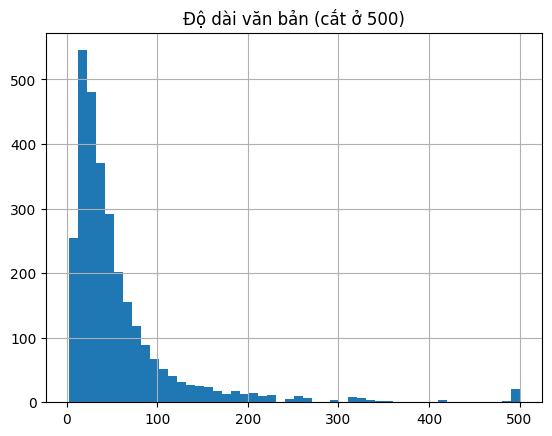

In [2]:
df = pd.read_csv(DATA)
print(df.shape); display(df.head())
print(df.kind.value_counts(), "\n", df.group.value_counts())
print("Trùng text:", df.text.duplicated().sum(), "| text rỗng:", df.text.isna().sum())
df["len"] = df.text.str.len()
df.len.clip(upper=500).hist(bins=50); plt.title("Độ dài văn bản (cắt ở 500)"); plt.show()

## 2. Gán nhãn SPAM / HAM
Theo guideline của nhóm (sheet `Dataset_Label`):
- **SPAM**: quảng cáo/chào mời dịch vụ–khóa học–tuyển dụng của trung tâm/công ty, bình luận “seeding” lặp lại, bán key/tài liệu, nội dung phát tán hàng loạt.
- **HAM**: hỏi đáp, trao đổi thông tin, **cả việc sinh viên tự pass đồ/tìm trọ đúng ngữ cảnh**; chỉ có `ib`, số điện thoại, bình luận ngắn, teencode, emoji **không** phải spam.
- **REVIEW**: ca mơ hồ (vd quảng bá CLB, thông báo của trường) → loại khỏi huấn luyện, xuất ra `review_candidates.csv` để 2 thành viên kiểm tra.

Cách làm: (1) luật regex; (2) danh sách ghi đè sau khi đọc tay các ứng viên (`SPAM_FORCE`, `HAM_FORCE`, `REVIEW_FORCE`, theo chỉ số dòng của `raw_fb.csv`).

In [3]:
t = df.text.fillna("").str.lower()
R = lambda p: t.str.contains(p, regex=True)

promo_course = R(r"aptis one|cam kết đầu ra|khóa ôn|khoá ôn|khóa học aptis|web luyện|lộ trình (?:rõ|tinh|từ|ôn|chi)|giáo viên band|gv band|ưu đãi hphi|ưu đãi nữa|nhận ôn aptis|inbox bên chị|bên chị có|bên c có")
sell_key   = R(r"full key|key update|có tài liệu ôn|có tài liệu,|đang gom aptis|mua key")
company    = R(r"tuyển dụng|tuyển cộng tác|tuyển thực tập|thực tập sinh kinh doanh|bna vietnam|smile media")
page_post  = (df.kind == "post") & df.text.fillna("").str.match(r"^\s*[📢🚨🏍📚💌📸✨🌷🎓🔥💥📌⭐]") & R(r"zalo|đăng ký|đăng kí|liên hệ|aptis|livestream|cảnh báo")
dup3       = df.text.map(df.text.value_counts()) >= 3
dup_promo  = dup3 & (promo_course | R(r"cam kết|khóa|khoá|\bib\b|\blh\b|liên hệ|zalo")) & (df.text.str.len() > 25)
ask_post   = R(r"ở đâu|chỗ nào|có ai|ai biết|cho em hỏi|có nơi nào|giới thiệu cho") & (df.kind == "post") & (df.text.str.len() < 200)
rule_spam  = (promo_course | sell_key | company | page_post | dup_promo) & ~ask_post
rule_review = R(r"clb|câu lạc bộ|rcm") & R(r"tuyển|ứng tuyển|đơn|rcm") & ~rule_spam

# Duyệt tay (chỉ số dòng trong raw_fb.csv)
HAM_FORCE = {1077, 2499, 2501, 1268, 1370, 1483, 1722, 2040, 2666, 2674, 2676, 2756}  # luật bắt nhầm: tự đăng trọ, hỏi/đáp thật
SPAM_FORCE = {634, 1375, 1367, 2700, 2751, 2757, 2758, 2759, 2734, 2810}              # seeding ngầm cho trung tâm
REVIEW_FORCE = {1265, 1073}                                                             # bán hộ/thông báo của trường: mơ hồ

label = np.where(rule_spam, "SPAM", "HAM").astype(object)
label[rule_review.values] = "REVIEW"
for i in HAM_FORCE:    label[i] = "HAM"
for i in SPAM_FORCE:   label[i] = "SPAM"
for i in REVIEW_FORCE: label[i] = "REVIEW"
df["label"] = label
df["label_source"] = "rules+manual"
print(df.label.value_counts())
print(df[df.label == "SPAM"].groupby("group").size())
df[df.label == "REVIEW"].to_csv(f"{OUT}/review_candidates.csv", index=False)
df.to_csv(f"{OUT}/raw_fb_labeled.csv", index=False)
pd.set_option("display.max_colwidth", 120)
display(df[df.label == "SPAM"][["kind", "text"]].sample(12, random_state=SEED))

label
HAM       2853
SPAM        68
REVIEW      27
Name: count, dtype: int64
group
1130813927934700    31
1542129366737375     3
584397217391365     11
confessions.ptit     2
ptit.onthi.aptis    15
sinhvienptithn       6
dtype: int64


,kind,text
2029,post,CẤU TRÚC CHI TIẾT APTIS ESOL GENERAL CHUẨN (Kèm đề mẫu)✨ Grammar & Vocabulary (30 câu)Grammar: 25 câu trắc nghiệm.Vo...
1314,comment,Full key Aptis tháng 10 giá 35 cá ib zalo: <PHONE>
580,post,"APTIS B1-B2 - SPEAKING PART 4Nhiều bạn nghĩ Part 4 khó nhất vì phải nói sâu, nhưng thực ra đây lại là phần dễ lấy đi..."
1023,comment,"Em có thể tham khảo BNA Vietnam nha, bên này hiện đang tuyển thành viên cho các ban HR, Marcom, RND, chủ yếu là cho ..."
1448,comment,"Mình vừa thi có tài liệu ôn, key update, form tự soạn, web, bạn cần thì lh <PHONE>"
1558,comment,ib mình đang gom aptis nhé <PHONE>
2734,comment,"Có B1 là miễn hết nha, mới tìm hiểu thì em tham khảo thử Aptis One nhe, cx có nhiều bạn trường mình học lúm. Gv trun..."
595,comment,"Bạn nào đang cần thi Aptis B1-B2 có thể tham khảo học Aptis One nha. Aptis One có lộ trình học nhanh gọn, giáo viên ..."
2753,comment,"Em tham khảo Aptis One nha. Bên chị có các gv band C nhiều kn, web luyện đề riêng tích hợp AI chấm chữa và có gv sửa..."
1222,post,"💌 TIN NHẮN KHIẾN THẦY CÔ APTIS ONE VUI CẢ NGÀY ĐÂY RỒI 💌Có những tin nhắn nhìn qua chỉ vài dòng thôi, nhưng với thầy..."


## 3. Tiền xử lý
Chuẩn hóa Unicode NFC + lowercase → thay URL/SĐT/số/mention bằng token → bỏ emoji, ký tự lặp → mở rộng teencode → tách từ (PyVi) → bỏ stop words (giữ `ib`, `liên_hệ`, `zalo`… vì là tín hiệu spam). Với PhoBERT chỉ chuẩn hóa nhẹ + tách từ, **giữ stop words**.

In [4]:
URL = re.compile(r"(https?://\S+|www\.\S+)")
TEEN = {"ko":"không","k":"không","đc":"được","dc":"được","bn":"bạn","vs":"với","mk":"mình","mik":"mình",
        "bt":"biết","mn":"mọi người","mng":"mọi người","j":"gì","r":"rồi","cx":"cũng","sv":"sinh viên",
        "ctv":"cộng tác viên","tl":"trả lời","trc":"trước","hphi":"học phí","gv":"giáo viên"}
STOP = set("và là của có những các một này đó ở thì mà cũng đã sẽ đang bị được cho với để trong khi như nhưng nên vì nếu rằng thế vậy ạ nhé nha nhỉ hả ơi à ừ ờ thôi lại rất quá cả mỗi từ tại về ra vào lên xuống nào ai gì đâu sao".split())

def normalize(s):
    s = unicodedata.normalize("NFC", str(s)).lower()
    s = URL.sub(" url ", s)
    s = s.replace("<user>", " mention ").replace("<phone>", " sdt ")
    s = re.sub(r"(?<!\d)0\d{9,10}(?!\d)", " sdt ", s)
    s = re.sub(r"\d+", " num ", s)
    s = re.sub(r"(.)\1{2,}", r"\1", s)
    s = re.sub(r"[^\w\s_]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def teen(s):   return " ".join(TEEN.get(w, w) for w in s.split())
def seg(s):    return ViTokenizer.tokenize(s)
def prep_classic(s): return " ".join(w for w in seg(teen(normalize(s))).split() if w not in STOP)
def prep_bert(s):    return seg(teen(normalize(s)))

print(prep_classic("MN ơi!!! vào http://bit.ly/abc xem sale 50% ib 0912345678 nha 💥💥"))
print(prep_classic("Có thể tham khảo Aptis One nha. Bên mình có lộ trình học tinh gọn, giáo viên band C"))

mọi người url xem sale num ib sdt
có_thể tham_khảo aptis one bên mình lộ_trình học tinh_gọn giáo_viên band c


## 4. Chia dữ liệu
Bỏ `REVIEW`, bỏ text rỗng/trùng, rồi chia **~80/20 theo `post_id`** (`StratifiedGroupKFold`) để các bình luận cùng một bài không nằm đồng thời ở train và test (tránh rò rỉ). SPAM là lớp dương.

In [5]:
d = df[df.label.isin(["HAM", "SPAM"]) & df.text.notna()].copy()
d = d.drop_duplicates(subset="text").reset_index(drop=True)
d["y"] = (d.label == "SPAM").astype(int)
d["x_classic"] = d.text.map(prep_classic)
d["x_bert"] = d.text.map(prep_bert)
d = d[d.x_classic.str.len() > 0].reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, te_idx = next(sgkf.split(d, d.y, groups=d.post_id))
tr, te = d.iloc[tr_idx].reset_index(drop=True), d.iloc[te_idx].reset_index(drop=True)
print(f"Tổng {len(d)} | train {len(tr)} (SPAM {tr.y.sum()}) | test {len(te)} (SPAM {te.y.sum()})")
assert not set(tr.post_id) & set(te.post_id)

Tổng 2807 | train 2295 (SPAM 45) | test 512 (SPAM 11)


## 5. Trích đặc trưng + mô hình baseline (BoW/TF-IDF × Naive Bayes/SVM)
Vectorizer nằm **trong `Pipeline`** nên chỉ fit trên train (không leakage). Tinh chỉnh bằng `GridSearchCV` (3-fold theo nhóm bài đăng, tối ưu F1 của lớp SPAM). SVM dùng `class_weight="balanced"` vì SPAM là lớp thiểu số.

In [6]:
def metrics(name, feat, y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(Model=name, Feature=feat, Accuracy=accuracy_score(y, p), Precision=precision_score(y, p, zero_division=0),
                Recall=recall_score(y, p), F1=f1_score(y, p), TN=tn, FP=fp, FN=fn, TP=tp)

VEC = {"BoW": CountVectorizer, "TF-IDF": TfidfVectorizer}
CLF = {"Naive Bayes": (MultinomialNB(), {"clf__alpha": [0.1, 0.5, 1.0]}),
       "SVM": (LinearSVC(class_weight="balanced", random_state=SEED), {"clf__C": [0.1, 1, 10]})}
GRID = {"vec__ngram_range": [(1, 1), (1, 2)], "vec__min_df": [1, 2]}
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)

rows, best, preds = [], [], {}
for cn, (clf, g) in CLF.items():
    for vn, V in VEC.items():
        gs = GridSearchCV(Pipeline([("vec", V()), ("clf", clf)]), {**GRID, **g}, scoring="f1", cv=cv, n_jobs=-1)
        gs.fit(tr.x_classic, tr.y, groups=tr.post_id)
        p = gs.predict(te.x_classic); preds[(cn, vn)] = p
        r = metrics(cn, vn, te.y, p); r["CV_F1"] = gs.best_score_; rows.append(r)
        best.append(dict(Model=cn, Feature=vn, **gs.best_params_))
base = pd.DataFrame(rows)
display(pd.DataFrame(best)); display(base.round(4))

,Model,Feature,clf__alpha,vec__min_df,vec__ngram_range,clf__C
0,Naive Bayes,BoW,0.5,2,"(1, 1)",NaN
1,Naive Bayes,TF-IDF,0.1,2,"(1, 2)",NaN
2,SVM,BoW,NaN,2,"(1, 2)",0.1
3,SVM,TF-IDF,NaN,1,"(1, 2)",1.0


,Model,Feature,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,CV_F1
0,Naive Bayes,BoW,0.9824,0.5714,0.7273,0.6400,495,6,3,8,0.7184
1,Naive Bayes,TF-IDF,0.9863,0.7500,0.5455,0.6316,499,2,5,6,0.7021
2,SVM,BoW,0.9902,1.0000,0.5455,0.7059,501,0,5,6,0.7216
3,SVM,TF-IDF,0.9922,1.0000,0.6364,0.7778,501,0,4,7,0.7696


## 6. Mô hình hiện đại: fine-tune PhoBERT
`vinai/phobert-base`, đầu vào đã tách từ, loss có trọng số lớp, chọn epoch tốt nhất theo F1 trên validation (~1/6 train, tách theo nhóm bài đăng).

Device: cpu


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 14997.87it/s]


[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'epoch': 1, 'train_loss': 0.7240187933705211, 'val_f1': 0.2222222222222222}


{'epoch': 2, 'train_loss': 0.3374764911440183, 'val_f1': 0.2222222222222222}


{'epoch': 3, 'train_loss': 0.1390095568891812, 'val_f1': 0.36363636363636365}


{'epoch': 4, 'train_loss': 0.1609657138900992, 'val_f1': 0.4}


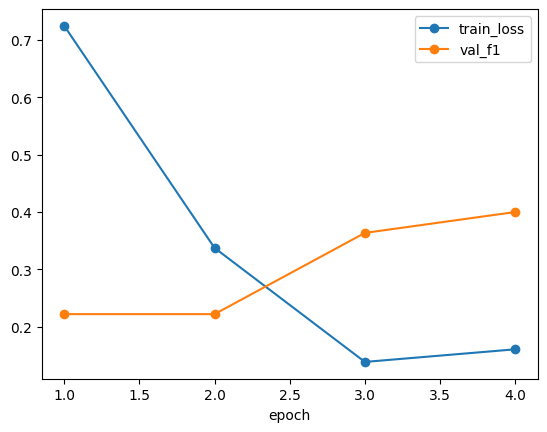

In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
torch.manual_seed(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)
EPOCHS, BS, LR, MAXLEN = 4, 16, 3e-5, 96

tr2_i, va_i = next(StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED).split(tr, tr.y, groups=tr.post_id))
tr2, va = tr.iloc[tr2_i].reset_index(drop=True), tr.iloc[va_i].reset_index(drop=True)

tok = AutoTokenizer.from_pretrained("vinai/phobert-base")
bert = AutoModelForSequenceClassification.from_pretrained("vinai/phobert-base", num_labels=2).to(dev)

def encode(texts):
    return tok(list(texts), truncation=True, max_length=MAXLEN, padding=True, return_tensors="pt")

@torch.no_grad()
def predict(frame):
    bert.eval(); out = []
    for i in range(0, len(frame), 32):
        e = {k: v.to(dev) for k, v in encode(frame.x_bert[i:i+32]).items()}
        out.append(bert(**e).logits.argmax(-1).cpu())
    return torch.cat(out).numpy()

w = torch.tensor([1.0, (tr2.y == 0).sum() / max((tr2.y == 1).sum(), 1)], dtype=torch.float).to(dev)
lossf = torch.nn.CrossEntropyLoss(weight=w)
opt = torch.optim.AdamW(bert.parameters(), lr=LR, weight_decay=0.01)
hist, best_f1, best_state = [], -1, None
for ep in range(EPOCHS):
    bert.train(); perm = np.random.permutation(len(tr2)); tot = 0
    for i in range(0, len(perm), BS):
        b = tr2.iloc[perm[i:i+BS]]
        e = {k: v.to(dev) for k, v in encode(b.x_bert).items()}
        loss = lossf(bert(**e).logits, torch.tensor(b.y.values).to(dev))
        loss.backward(); torch.nn.utils.clip_grad_norm_(bert.parameters(), 1.0); opt.step(); opt.zero_grad()
        tot += loss.item() * len(b)
    vf = f1_score(va.y, predict(va))
    hist.append(dict(epoch=ep + 1, train_loss=tot / len(tr2), val_f1=vf)); print(hist[-1])
    if vf > best_f1: best_f1, best_state = vf, {k: v.detach().clone() for k, v in bert.state_dict().items()}
bert.load_state_dict(best_state)
p_bert = predict(te)
r = metrics("PhoBERT", "Tokenizer/Embedding", te.y, p_bert); r["CV_F1"] = best_f1
pd.DataFrame(hist).plot(x="epoch", y=["train_loss", "val_f1"], marker="o"); plt.show()

## 7. Đánh giá & so sánh

,Model,Feature,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,CV_F1
0,Naive Bayes,BoW,0.9824,0.5714,0.7273,0.6400,495,6,3,8,0.7184
1,Naive Bayes,TF-IDF,0.9863,0.7500,0.5455,0.6316,499,2,5,6,0.7021
2,SVM,BoW,0.9902,1.0000,0.5455,0.7059,501,0,5,6,0.7216
3,SVM,TF-IDF,0.9922,1.0000,0.6364,0.7778,501,0,4,7,0.7696
4,PhoBERT,Tokenizer/Embedding,0.9824,1.0000,0.1818,0.3077,501,0,9,2,0.4000


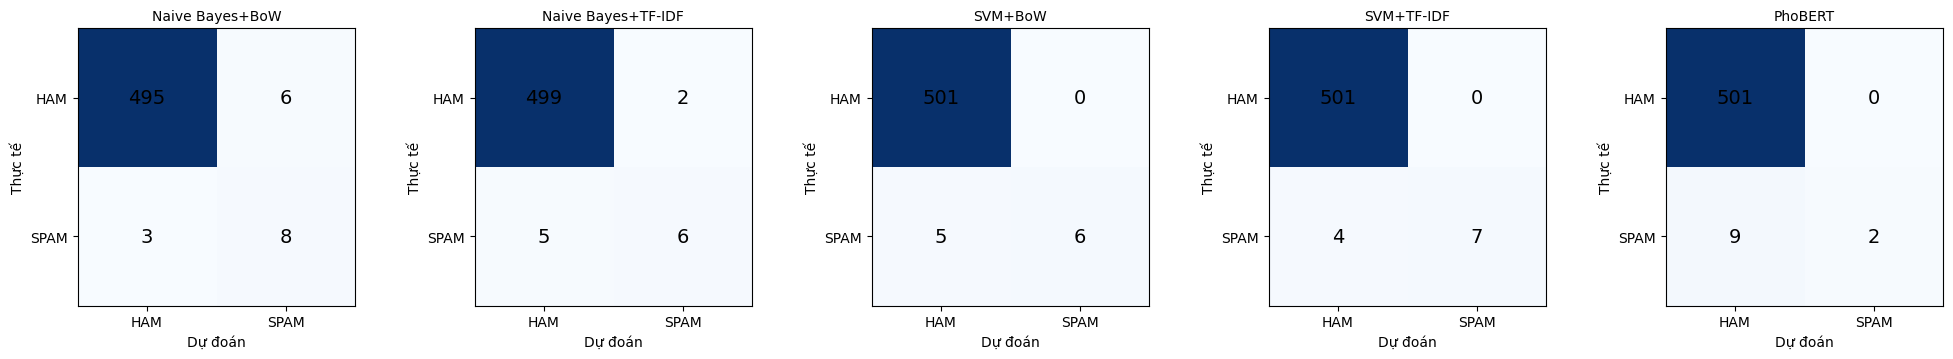

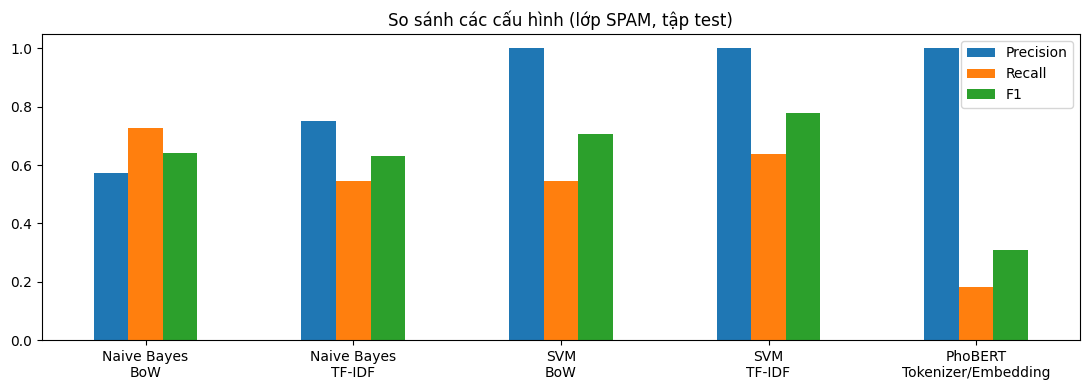

In [8]:
res = pd.concat([base, pd.DataFrame([r])], ignore_index=True)
res.to_csv(f"{OUT}/metrics.csv", index=False)
display(res.round(4))

allp = {**{f"{m}+{f}": p for (m, f), p in preds.items()}, "PhoBERT": p_bert}
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (n, p) in zip(axes, allp.items()):
    cm = confusion_matrix(te.y, p, labels=[0, 1]); ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
    ax.set_xticks([0, 1], ["HAM", "SPAM"]); ax.set_yticks([0, 1], ["HAM", "SPAM"]); ax.set_title(n, fontsize=10)
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices.png", dpi=150); plt.show()

ax = res.set_index(res.Model + "\n" + res.Feature)[["Precision", "Recall", "F1"]].plot.bar(rot=0, figsize=(11, 4), ylim=(0, 1.05))
plt.title("So sánh các cấu hình (lớp SPAM, tập test)"); plt.tight_layout(); plt.savefig(f"{OUT}/compare.png", dpi=150); plt.show()

### Phân tích lỗi

In [9]:
errs = []
for n, p in allp.items():
    errs.append(te.assign(pred=p, model=n)[te.y != p])
errs = pd.concat(errs)
errs["loai_loi"] = np.where(errs.y == 1, "FN (lọt spam)", "FP (chặn nhầm)")
errs[["model", "loai_loi", "kind", "text"]].to_csv(f"{OUT}/errors.csv", index=False)
print(errs.groupby(["model", "loai_loi"]).size().unstack(fill_value=0))
display(errs[errs.model == "PhoBERT"][["loai_loi", "text"]].head(15))
display(errs.groupby("text").model.nunique().sort_values(ascending=False).head(10))   # câu bị nhiều mô hình sai cùng lúc

loai_loi            FN (lọt spam)  FP (chặn nhầm)
model                                            
Naive Bayes+BoW                 3               6
Naive Bayes+TF-IDF              5               2
PhoBERT                         9               0
SVM+BoW                         5               0
SVM+TF-IDF                      4               0


,loai_loi,text
85,FN (lọt spam),C có khóa ôn CAM KẾT ĐẦU RA B1 – B2 – C nha 💯
118,FN (lọt spam),"Cô <USER> e nha, với sự nhiệt tình 1000% của cô thì học auto điểm cao nha, cô sát sao học sinh lắm, chểnh mảng là cô..."
251,FN (lọt spam),📚 APTIS WRITING PART 4 – BÍ QUYẾT CHINH PHỤC ĐIỂM CAO! ✨Writing Part 4 luôn là phần khiến nhiều bạn loay hoay vì khô...
258,FN (lọt spam),Bên Chị có khóa ôn Toeic/IELTS
264,FN (lọt spam),ib mình đang gom aptis nhé <PHONE>
332,FN (lọt spam),CẤU TRÚC CHI TIẾT APTIS ESOL GENERAL CHUẨN (Kèm đề mẫu)✨ Grammar & Vocabulary (30 câu)Grammar: 25 câu trắc nghiệm.Vo...
472,FN (lọt spam),"Có B1 là miễn hết nha, mới tìm hiểu thì em tham khảo thử Aptis One nhe, cx có nhiều bạn trường mình học lúm. Gv trun..."
476,FN (lọt spam),Web của aptis one có AI chấm chữa nên tự học ổn á
477,FN (lọt spam),Cố bỏ ra xíu dki aptis one cậu oii


text
Cô <USER> e nha, với sự nhiệt tình 1000% của cô thì học auto điểm cao nha, cô sát sao học sinh lắm, chểnh mảng là cô inbox cho liền, tại cô soi btvn mình nên mà làm vớ vẩn là biết ngay, nm đúng là áp lực tạo kim cương, có cô dí nên vào khuôn khổ, đi thi được 830 RL với 320 SW, haha, flex tý                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

## 8. Kết luận
Xem bảng ở mục 7 để so sánh BoW vs TF-IDF và NB vs SVM vs PhoBERT. Khi diễn giải cần nhớ:
1. Tập test nhỏ và lệch lớp (SPAM là thiểu số) → chênh lệch vài mẫu làm F1 dao động mạnh; nên báo cáo kèm Confusion Matrix.
2. Nhãn là **nhãn yếu** (luật + duyệt tay) → mô hình có thể chỉ học lại luật. Việc cần làm: 2 thành viên gán độc lập một tập mẫu, đo Cohen's kappa, xử lý các dòng `REVIEW`.
3. SPAM tập trung ở ít chủ đề (khóa học Aptis, bán key, tuyển dụng) nên khả năng tổng quát hóa sang spam kiểu khác chưa được kiểm chứng.